# ACT Performance, Married-Couple Families, and Charter Schools

**Research question:** Do charter status (charter vs. non-charter) and/or the share of children in married-couple
families (`percent_married`) relate to a school's average ACT score?

This notebook repeats the analysis from `Education_exploratory_data.ipynb` (code cell 15 onward), using
**CT Pct Children In Married Couple Family** (`percent_married`) as the main variable in place of `median_income`,
and brings **charter** status into each step. It ends with robustness checks (robust standard errors, dropping
extreme `percent_married` values, and state fixed effects) and a summary that answers the research question.

## Import libraries

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Statistical tests
from scipy import stats

# Loading Data

In [2]:
df = pd.read_csv("/Users/williamdang/Documents/Education/Data/education_clean.csv")

## Define the two groups
Same grouping as before: Kentucky's `Not applicable` schools are regular public schools, so they go with `No`.

- **Charter** = `Yes`
- **Non-charter** = `No` + `Not applicable`

We also make a 0/1 column `is_charter` (1 = charter) so the regression coefficient reads directly as
"charter minus non-charter".

In [3]:
df["group"] = np.where(df["charter"] == "Yes", "Charter", "Non-charter")
df["is_charter"] = (df["group"] == "Charter").astype(int)
df["group"].value_counts()

group
Non-charter    7057
Charter         170
Name: count, dtype: int64

# ACT Scores: Charter vs. Non-Charter High Schools

First, the direct comparison: do charter and non-charter schools differ in average ACT?

## Summary statistics of average_act by group

In [ ]:
act_summary = df.groupby("group")["average_act"].agg(["count", "mean", "median", "std", "min", "max"]).round(3)
act_summary

In [ ]:
charter_act = df.loc[df["group"] == "Charter", "average_act"]
non_charter_act = df.loc[df["group"] == "Non-charter", "average_act"]

print(f"Difference in means (charter − non-charter):   {charter_act.mean() - non_charter_act.mean():.3f}")
print(f"Difference in medians:                         {charter_act.median() - non_charter_act.median():.3f}")

In [ ]:
sns.boxplot(data=df, x="group", y="average_act", hue="group",
            legend=False, width=0.5)
plt.xlabel("")
plt.ylabel("Average ACT score")
plt.title("Average ACT by school type")

plt.tight_layout()
plt.show()

## Is the ACT difference statistically significant?

Welch's two-sample t-test (no equal-variance assumption, because the groups differ in size and spread).

Null hypothesis: charter and non-charter schools have the same mean `average_act`.
Alternative: the means are different.
Significance level: α = 0.05

In [ ]:
t_act = stats.ttest_ind(charter_act, non_charter_act, equal_var=False)   # Welch's t-test
ci_act = t_act.confidence_interval(confidence_level=0.95)

print(f"t-statistic: {t_act.statistic:.2f}")
print(f"p-value:     {t_act.pvalue:.2e}")
print(f"95% CI for the difference in means: [{ci_act.low:.3f}, {ci_act.high:.3f}]")

**Interpretation**:
Charter schools average about **19.0** on the ACT and non-charter schools about **20.3**, a gap of **1.31 points**
(medians 18.9 vs 20.5, a 1.65-point gap). Welch's test gives t ≈ −5.39 and p ≈ 2.2e-7, so we reject the null hypothesis.
The 95% confidence interval for the gap is roughly −1.79 to −0.83 points.

Charter scores are also more spread out (std 3.14 vs 2.48). Because the spread differs, the robustness checks later
use standard errors that do not assume equal variance.

The rest of the notebook asks whether this gap remains once we account for the communities the schools serve.

# Married-Couple Families: Charter vs. Non-Charter High Schools

Before modeling ACT, check whether charter and non-charter schools serve communities with a different share
of children in married-couple families.

## Summary statistics of percent_married by group

In [4]:
summary = df.groupby("group")["percent_married"].agg(["count", "mean", "median", "std", "min", "max"]).round(3)
summary

,count,mean,median,std,min,max
group,,,,,,
Charter,170,0.492,0.487,0.235,0.0,1.0
Non-charter,7057,0.644,0.674,0.189,0.0,1.0


In [5]:
charter_married = df.loc[df["group"] == "Charter", "percent_married"]
non_charter_married = df.loc[df["group"] == "Non-charter", "percent_married"]

print(f"Difference in means (charter − non-charter):   {charter_married.mean() - non_charter_married.mean():.3f}")
print(f"Difference in medians:                         {charter_married.median() - non_charter_married.median():.3f}")

Difference in means (charter − non-charter):   -0.152
Difference in medians:                         -0.187


**Interpretation**:
In the communities around charter schools, about 49% of children live in married-couple families, compared with
about 64% around non-charter schools, a gap of roughly 15 percentage points (medians: 48.7% vs 67.4%).
Charter schools are also more spread out on this variable (std 0.235 vs 0.189).

## Create a plot to visualize

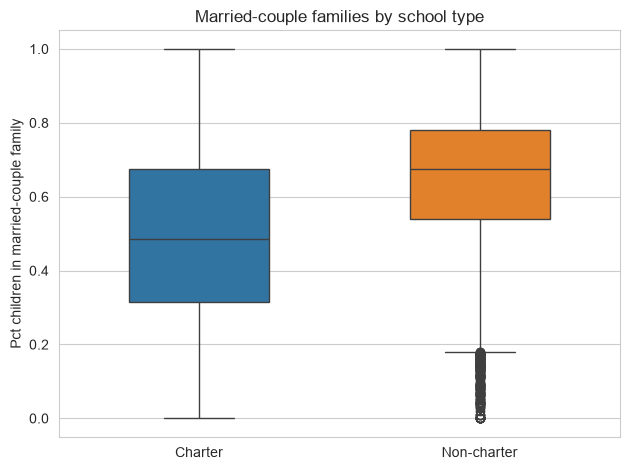

In [6]:
sns.boxplot(data=df, x="group", y="percent_married", hue="group",
            legend=False, width=0.5)
plt.xlabel("")
plt.ylabel("Pct children in married-couple family")
plt.title("Married-couple families by school type")

plt.tight_layout()
plt.show()

## Is the difference statistically significant?

Welch's two-sample t-test (no equal-variance assumption, because the groups differ in size and spread).

Null hypothesis: charter and non-charter schools have the same mean `percent_married`.
Alternative: the means are different.
Significance level: α = 0.05

In [7]:
t_result = stats.ttest_ind(charter_married, non_charter_married, equal_var=False)   # Welch's t-test
ci = t_result.confidence_interval(confidence_level=0.95)

print(f"t-statistic: {t_result.statistic:.2f}")
print(f"p-value:     {t_result.pvalue:.2e}")
print(f"95% CI for the difference in means: [{ci.low:.3f}, {ci.high:.3f}]")

t-statistic: -8.37
p-value:     1.82e-14
95% CI for the difference in means: [-0.188, -0.116]


## Interpretation

The p-value (about 1.8e-14) is far below 0.05, so we reject the null hypothesis: charter schools serve communities
with a significantly lower share of children in married-couple families. The 95% confidence interval is roughly
−0.19 to −0.12, so charter communities have about 12 to 19 percentage points fewer children in married-couple families.

This matters for the ACT comparison: if `percent_married` is linked to ACT, part of the 1.3-point ACT gap between charter and non-charter schools (found above)
may reflect who the schools serve rather than the schools themselves. The models below test that.

## Modeling

# Single input model: percent_married
Plot the regression line and scatterplot

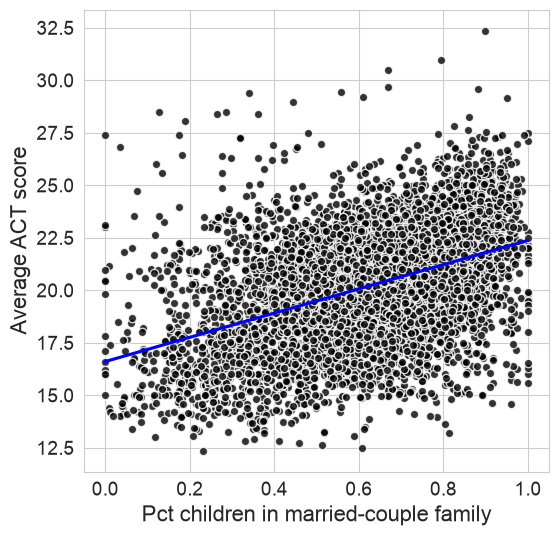

In [8]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='percent_married',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Pct children in married-couple family', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

# Fit the simple linear regression model

In [9]:
model_married = smf.ols(formula='average_act ~ percent_married', data=df).fit()
print(model_married.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.193
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     1733.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:07   Log-Likelihood:                -16124.
No. Observations:                7227   AIC:                         3.225e+04
Df Residuals:                    7225   BIC:                         3.227e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          16.6046      0.093    1

# Compute the R-squared

In [10]:
model_married.rsquared

np.float64(0.19344634795873594)

# Compute the RMSE

In [11]:
y_hat = model_married.predict()
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

np.float64(2.253)

# Compute the mean absolute error

In [12]:
mean_absolute_error(df['average_act'], y_hat)

1.7361820917022264

**Interpretation**:
The slope is about 5.77: going from 0% to 100% of children in married-couple families is associated with about
5.8 more ACT points, or about **0.58 points for every 10 percentage points**. The relationship is highly significant
(t ≈ 41.6, p < 0.001).

`percent_married` alone explains about 19.3% of the variation in ACT (R² = 0.193), slightly less than
`median_income` (R² = 0.211). RMSE ≈ 2.25 and MAE ≈ 1.74 ACT points, also a bit worse than median income
(2.23 and 1.71).

Use a residual plot for graphical assessment of model fit

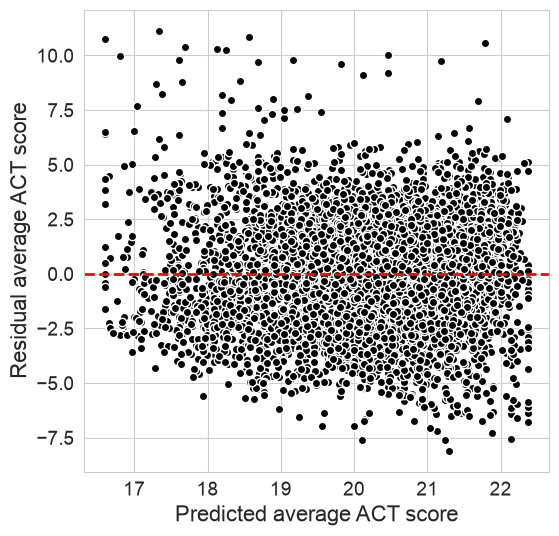

In [13]:
plt.figure(figsize=(6, 6))

plt.plot(y_hat, model_married.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

**Interpretation**: The residuals are spread fairly evenly around zero. Watch for the vertical stripes at the far
left and right of the plot: 14 schools have `percent_married` = 0 and 21 have 1, which usually means a very small
census tract, so those values are less reliable.

Compare the linear and quadratic fits

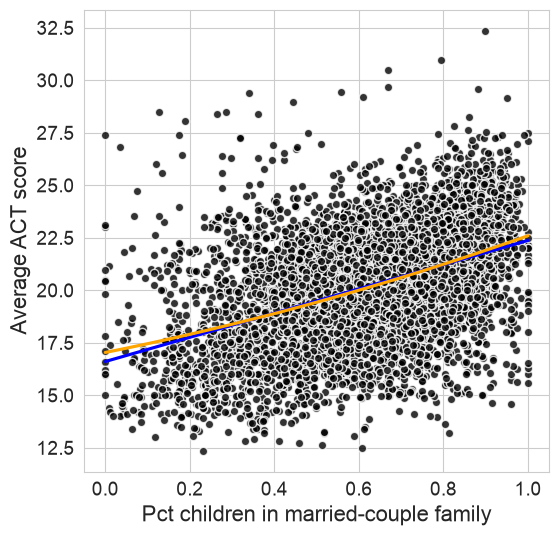

In [14]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='percent_married',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data=df,
            x='percent_married',
            y='average_act',
            order=2,
            color='orange',
            ci=False,
            scatter=False)

# Add axis labels
plt.xlabel('Pct children in married-couple family', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

Fit a quadratic linear regression model

In [15]:
model_married2 = smf.ols(
    formula='average_act ~ percent_married + I(percent_married**2)',
    data=df).fit()

In [16]:
print(model_married2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.194
Model:                            OLS   Adj. R-squared:                  0.194
Method:                 Least Squares   F-statistic:                     871.1
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:07   Log-Likelihood:                -16120.
No. Observations:                7227   AIC:                         3.225e+04
Df Residuals:                    7224   BIC:                         3.227e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

# Assess the model significance

In [17]:
model_married2.pvalues

Intercept                  0.000000e+00
percent_married            3.960491e-10
I(percent_married ** 2)    5.236571e-03
dtype: float64

In [18]:
anova_lm(model_married, model_married2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,36671.604473,0.0,NaN,NaN,NaN
1,7224.0,36632.048448,1.0,39.556025,7.800621,0.005237


# Compare the quadratic model accuracy to the first order model

In [19]:
mean_absolute_error(df['average_act'], model_married2.predict())

1.7377630208767738

In [20]:
mean_absolute_error(df['average_act'], model_married.predict())

1.7361820917022264

**Interpretation**:
The squared term is statistically significant (p ≈ 0.005, ANOVA F ≈ 7.8), and its coefficient is positive,
so the curve bends slightly **upward**: the link with ACT gets a little stronger at high `percent_married`.
(Median income was the opposite: its curve flattened at high incomes.)

In practice the improvement is tiny. R² only rises from 0.1934 to 0.1943, and the MAE does not improve at all
(1.738 vs 1.736). The two lines in the plot are almost on top of each other. With 7,227 schools even a very small
effect becomes "significant", so the simpler linear model is the better choice here.

# Adding charter status

Now we ask: does charter status still matter for ACT once we account for `percent_married`,
and is the `percent_married`–ACT relationship the same in both types of school?

Plot a separate regression line for each group

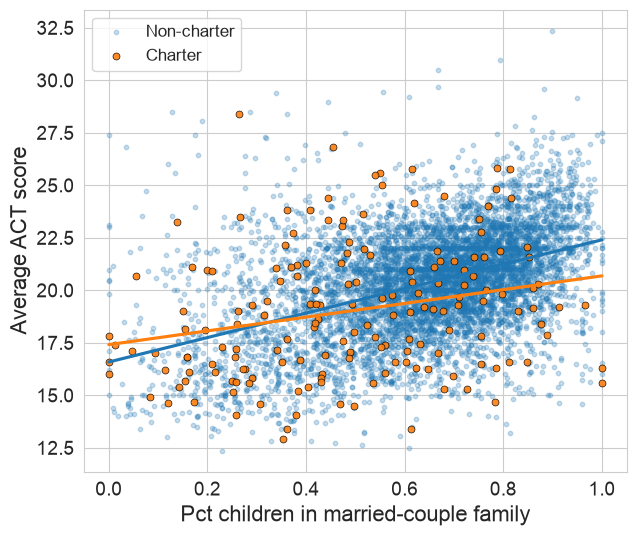

In [21]:
plt.figure(figsize=(7, 6))

sns.regplot(data=df[df['group'] == 'Non-charter'],
            x='percent_married',
            y='average_act',
            color='tab:blue',
            ci=False,
            label='Non-charter',
            scatter_kws={'alpha': 0.25, 's': 10})

sns.regplot(data=df[df['group'] == 'Charter'],
            x='percent_married',
            y='average_act',
            color='tab:orange',
            ci=False,
            label='Charter',
            scatter_kws={'alpha': 0.9, 's': 25, 'edgecolors': 'k', 'linewidths': 0.5})

plt.xlabel('Pct children in married-couple family', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)
plt.tick_params(labelsize=14)
plt.legend(fontsize=12)

plt.show()

## Charter only (reproduces the raw gap)

In [22]:
model_charter = smf.ols(formula='average_act ~ is_charter', data=df).fit()
print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     45.53
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.62e-11
Time:                        12:27:08   Log-Likelihood:                -16878.
No. Observations:                7227   AIC:                         3.376e+04
Df Residuals:                    7225   BIC:                         3.377e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     20.3294      0.030    682.919      0.0

The `is_charter` coefficient (≈ −1.31) is exactly the difference in mean ACT found by the Welch t-test above
(19.02 − 20.33). Only the standard error differs, because ordinary regression assumes both groups have the same variance
and Welch's test does not. On its own, charter status explains less than 1% of the variation in ACT (R² ≈ 0.006).

## percent_married + charter

In [23]:
model_married_charter = smf.ols(
    formula='average_act ~ percent_married + is_charter',
    data=df).fit()
print(model_married_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.194
Model:                            OLS   Adj. R-squared:                  0.194
Method:                 Least Squares   F-statistic:                     870.1
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:08   Log-Likelihood:                -16121.
No. Observations:                7227   AIC:                         3.225e+04
Df Residuals:                    7224   BIC:                         3.227e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          16.6417      0.094    1

In [24]:
anova_lm(model_married, model_married_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,36671.604473,0.0,NaN,NaN,NaN
1,7224.0,36640.306843,1.0,31.297631,6.170638,0.013011


**Interpretation**:
After controlling for `percent_married`, the charter coefficient shrinks from **−1.31 to about −0.44** ACT points,
a drop of about two-thirds. With the default standard errors it is still significant (p ≈ 0.013), but with robust
standard errors it is only borderline (p ≈ 0.07, see *Robustness checks* below).
So most of the raw charter gap goes with the fact that charter schools serve communities with fewer
married-couple families. The `percent_married` slope hardly changes (5.77 → 5.73).

## Interaction: does the slope differ between charter and non-charter schools?

In [25]:
model_interaction = smf.ols(
    formula='average_act ~ percent_married * is_charter',
    data=df).fit()
print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.195
Model:                            OLS   Adj. R-squared:                  0.195
Method:                 Least Squares   F-statistic:                     584.8
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:08   Log-Likelihood:                -16115.
No. Observations:                7227   AIC:                         3.224e+04
Df Residuals:                    7223   BIC:                         3.227e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [26]:
anova_lm(model_married_charter, model_interaction)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7224.0,36640.306843,0.0,NaN,NaN,NaN
1,7223.0,36581.790093,1.0,58.516749,11.554013,0.00068


**Interpretation**:
The interaction term `percent_married:is_charter` is about −2.55 and significant (p ≈ 0.0007).
- Non-charter slope: about **5.82** ACT points per 0→100% change in `percent_married`.
- Charter slope: 5.82 − 2.55 ≈ **3.27**.

So ACT is less tied to family structure in charter schools than in regular public schools. Because the slopes differ,
the charter-vs-non-charter difference depends on the level of `percent_married`. The next cell finds where the two
lines cross and tests the charter difference at several levels. Keep in mind there are only 170 charter schools,
so the charter slope is much less precise.

## Where do the charter and non-charter lines cross?

In [ ]:
b = model_interaction.params
crossover = -b["is_charter"] / b["percent_married:is_charter"]
print(f"Lines cross at percent_married ≈ {crossover:.3f}")
print(f"Share of charter schools below the crossover:     {(charter_married < crossover).mean():.1%}")
print(f"Share of non-charter schools below the crossover: {(non_charter_married < crossover).mean():.1%}")

# Charter − non-charter difference at several levels of percent_married:
# is_charter + x * (percent_married:is_charter)
rows = []
for x in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    R = np.zeros(len(b))
    R[b.index.get_loc("is_charter")] = 1
    R[b.index.get_loc("percent_married:is_charter")] = x
    tt = model_interaction.t_test(R)
    ci_low, ci_high = np.squeeze(tt.conf_int())
    rows.append({"percent_married": x,
                 "charter − non-charter": float(np.squeeze(tt.effect)),
                 "CI low": ci_low,
                 "CI high": ci_high,
                 "p-value": float(np.squeeze(tt.pvalue))})

pd.DataFrame(rows).round(3)

**Interpretation**:
The lines cross at about **33% married**. About 26% of charter schools sit below that point, compared with only
7% of non-charter schools.
- Below about 40% married the charter difference is small and **not significant** (e.g. +0.32 at 20%, p ≈ 0.26).
  So the data do not support saying charters score *higher* in low-marriage communities.
- From about 50% married upward, charters score **significantly lower**: about −0.45 points at 50%, −0.95 at 70%,
  and −1.21 at 80% (all p < 0.05).

In other words, the charter gap shows up mainly in communities with many married-couple families.

Compare the models so far

In [27]:
models = {
    'percent_married':               model_married,
    'percent_married (quadratic)':   model_married2,
    'charter only':                  model_charter,
    'percent_married + charter':     model_married_charter,
    'percent_married * charter':     model_interaction,
}

pd.DataFrame({
    'R-squared':           [m.rsquared for m in models.values()],
    'Mean Absolute Error': [mean_absolute_error(df['average_act'], m.predict()) for m in models.values()],
    'RMSE':                [np.sqrt(mean_squared_error(df['average_act'], m.predict())) for m in models.values()],
}, index=models.keys()).round(4)

,R-squared,Mean Absolute Error,RMSE
percent_married,0.1934,1.7362,2.2526
percent_married (quadratic),0.1943,1.7378,2.2514
charter only,0.0063,1.9559,2.5004
percent_married + charter,0.1941,1.7352,2.2516
percent_married * charter,0.1954,1.7337,2.2498


## Multiple linear regression
Fit the multiple linear regression model using all socioeconomic variables plus charter status as predictors

In [28]:
model_full_charter = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + is_charter',
    data=df).fit()
print(model_full_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2032.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:08   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7220   BIC:                         2.672e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6976      0.13

Use a residual plot for graphical assessment of model fit

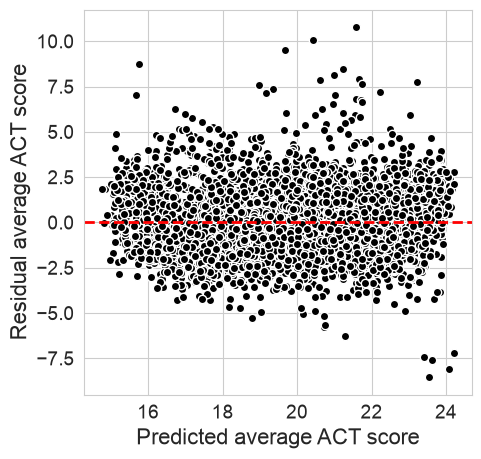

In [29]:
y_hat = model_full_charter.predict()

plt.figure(figsize=(5, 5))

plt.plot(y_hat, model_full_charter.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

Compute the mean absolute error

In [30]:
mean_absolute_error(df['average_act'], model_full_charter.predict())

1.1453200723344679

Does adding charter improve the full socioeconomic model?

In [31]:
model_full = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch',
    data=df).fit()

anova_lm(model_full, model_full_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7221.0,16915.612457,0.0,NaN,NaN,NaN
1,7220.0,16910.951259,1.0,4.661197,1.990062,0.158377


**Interpretation**:
With all five socioeconomic variables in the model, the charter coefficient is only about −0.17 and **not significant**
(p ≈ 0.16). The ANOVA agrees (p ≈ 0.16): adding charter does not improve the full model (R² 0.6280 → 0.6281).

`percent_married` also stops being significant here (coef ≈ −0.09, p ≈ 0.52), even though it was a strong predictor
on its own. The next cells check why.

## Why does `percent_married` drop out? Checking overlap between predictors

In [ ]:
ses_vars = ["rate_unemployment", "percent_college", "percent_married", "median_income", "percent_lunch"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[ses_vars + ["average_act"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlations among socioeconomic variables and ACT")
plt.tight_layout()
plt.show()

Variance inflation factors (VIF) for the full model. A VIF above about 5 would signal a collinearity problem.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(df[ses_vars + ["is_charter"]])
pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
          index=X_vif.columns[1:], name="VIF").round(2)

How much of the `percent_married` slope survives once free/reduced lunch is added?

In [ ]:
model_married_lunch = smf.ols(formula="average_act ~ percent_married + percent_lunch", data=df).fit()
print(model_married_lunch.params.round(3))
print(model_married_lunch.pvalues)
print(f"R-squared: {model_married_lunch.rsquared:.4f}")

**Interpretation**:
- `percent_married` is moderately correlated with every other socioeconomic variable: −0.56 with unemployment,
  +0.62 with median income, −0.52 with free/reduced lunch and +0.44 with college.
- All VIFs are low (about 1.6 to 2.7), so the estimates are **not** unstable. `percent_married` drops out because
  the information it carries is already in the other variables, not because of a collinearity problem.
- Adding only `percent_lunch` cuts the `percent_married` slope from **5.77 to 0.63** (still significant, p ≈ 2e-8).
  Most of the married–ACT link is shared with free/reduced lunch, and unemployment, college and income absorb the rest.
- The same overlap explains the small negative `median_income` coefficient in the full model (p ≈ 0.91).
  On its own, median income is positive (about +0.47 ACT points per $10,000).
- `is_charter` has a VIF of about 1.0. Charter status is nearly unrelated to the socioeconomic variables, so its
  drop toward zero is not caused by collinearity either.

## Fit a reduced model with the significant predictors (keeping charter)

In [32]:
model_reduced_charter = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch + is_charter',
    data=df).fit()
print(model_reduced_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     3048.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:08   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7222   BIC:                         2.670e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6322      0.10

Use a residual plot for graphical assessment of model fit

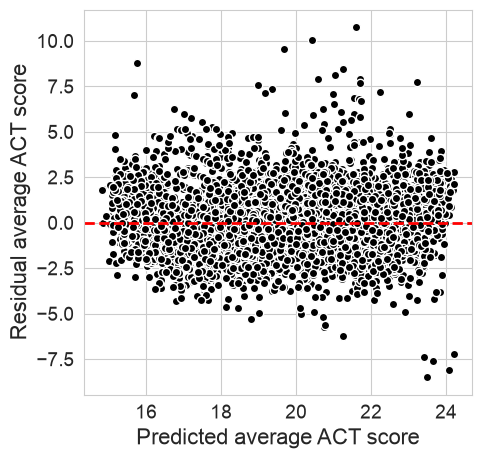

In [33]:
y_hat = model_reduced_charter.predict()

plt.figure(figsize=(5, 5))

plt.plot(y_hat, model_reduced_charter.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

Compute the mean absolute error

In [34]:
mean_absolute_error(df['average_act'], model_reduced_charter.predict())

1.1455111723690437

# Compare the accuracy between full and reduced models

In [35]:
model_reduced = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df).fit()

models = {
    'full + charter':    model_full_charter,
    'full':              model_full,
    'reduced + charter': model_reduced_charter,
    'reduced':           model_reduced,
}

pd.DataFrame({
    'Mean Absolute Error': [mean_absolute_error(df['average_act'], m.predict()) for m in models.values()],
    'R-squared':           [m.rsquared for m in models.values()],
}, index=models.keys()).round(4)

,Mean Absolute Error,R-squared
full + charter,1.1453,0.6281
full,1.1453,0.6280
reduced + charter,1.1455,0.6280
reduced,1.1455,0.6279


# Use ANOVA to test the significance of difference between models

In [36]:
anova_lm(model_reduced_charter, model_full_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7222.0,16912.272364,0.0,NaN,NaN,NaN
1,7220.0,16910.951259,2.0,1.321104,0.282018,0.754269


In [37]:
anova_lm(model_reduced, model_reduced_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7222.0,16912.272364,1.0,4.346804,1.856203,0.173106


**Interpretation**:
- Dropping `percent_married` and `median_income` from the full model costs nothing (ANOVA p ≈ 0.75; MAE 1.1453 vs 1.1455).
- Adding charter to the reduced model does not help either (p ≈ 0.17; charter coef ≈ −0.16).

All four models have R² ≈ 0.628, so the simple 3-variable reduced model from the original notebook is still the best choice.

## Scaling

Scale the numeric predictors in the reduced model to have mean 0 and standard deviation 1 and add them to the data frame.
`is_charter` stays as 0/1 so its coefficient keeps its meaning (charter minus non-charter, in ACT points).

In [38]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

In [39]:
scaled_columns = [var + '_normalized' for var in predictor_variables]

In [40]:
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


In [41]:
scaler = StandardScaler().fit(df[predictor_variables])

In [42]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

Check the mean and standard deviation of the transformed data

In [43]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


Fit the multiple linear regression model with the normalized predictors and charter

In [44]:
model_normalized_charter = smf.ols(
    formula='average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized + is_charter',
    data=df).fit()
print(model_normalized_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     3048.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:27:08   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7222   BIC:                         2.670e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

# Compare the accuracy between the original and normalized models

In [45]:
pd.DataFrame({
    'Mean Absolute Error': [mean_absolute_error(df['average_act'], m.predict())
                            for m in [model_reduced_charter, model_normalized_charter]],
    'R-squared':           [m.rsquared for m in [model_reduced_charter, model_normalized_charter]],
}, index=['reduced + charter', 'normalized + charter']).round(4)

,Mean Absolute Error,R-squared
reduced + charter,1.1455,0.628
normalized + charter,1.1455,0.628


**Interpretation**:
Scaling does not change the fit (same R² and MAE), but it makes the coefficients comparable. A one-standard-deviation
increase in `percent_lunch` goes with about **−1.78** ACT points, compared with **+0.28** for `percent_college` and
**−0.12** for `rate_unemployment`. Free/reduced lunch is by far the strongest predictor. The charter coefficient stays
at about −0.16 and is not significant.

# Robustness checks

Three checks on the main charter and `percent_married` results:
1. **Robust (HC3) standard errors**: the default standard errors assume equal variance, but charter ACT scores are more spread out.
2. **Drop extreme `percent_married` values**: 14 schools have exactly 0 and 21 have exactly 1, which usually means a very small census tract.
3. **State fixed effects**: ACT participation and charter laws differ a lot by state, so compare schools within the same state.

## 1. Robust (HC3) standard errors

In [ ]:
key_models = {
    "charter only":              model_charter,
    "percent_married":           model_married,
    "percent_married + charter": model_married_charter,
    "percent_married * charter": model_interaction,
    "full + charter":            model_full_charter,
    "reduced + charter":         model_reduced_charter,
}

rows = []
for name, m in key_models.items():
    m_hc3 = m.model.fit(cov_type="HC3")
    for term in m.params.index:
        if "charter" in term or "married" in term:
            rows.append({"model": name, "term": term,
                         "coef": m.params[term],
                         "p (default)": m.pvalues[term],
                         "p (HC3 robust)": m_hc3.pvalues[term]})

pd.DataFrame(rows).round(4)

**Interpretation**:
The coefficients do not change, only the p-values.
- `percent_married` alone, the raw charter gap, and the interaction (p ≈ 0.007) all stay significant.
- The charter coefficient after controlling for `percent_married` (−0.44) becomes **borderline** (p ≈ 0.07 instead of 0.013).
- In the full and reduced models, charter stays non-significant (p ≈ 0.28 and 0.29).

## 2. Drop schools with percent_married exactly 0 or 1

In [ ]:
df_trim = df[(df["percent_married"] > 0) & (df["percent_married"] < 1)]
print(f"{len(df)} -> {len(df_trim)} schools ({df_trim['is_charter'].sum()} charters)")

formulas = {
    "percent_married + charter": "average_act ~ percent_married + is_charter",
    "percent_married * charter": "average_act ~ percent_married * is_charter",
}

rows = []
for name, f in formulas.items():
    m_all = smf.ols(f, data=df).fit(cov_type="HC3")
    m_trim = smf.ols(f, data=df_trim).fit(cov_type="HC3")
    for term in m_all.params.index[1:]:
        rows.append({"model": name, "term": term,
                     "coef (all)": m_all.params[term], "p (all)": m_all.pvalues[term],
                     "coef (trimmed)": m_trim.params[term], "p (trimmed)": m_trim.pvalues[term]})

pd.DataFrame(rows).round(4)

**Interpretation**:
Dropping the 35 extreme schools (5 of them charters) changes little. The `percent_married` slope is about 5.9 and the
interaction is about −2.2 (robust p ≈ 0.03), so the weaker slope in charter schools is not driven by those tracts.
The charter coefficient after controlling for `percent_married` gets a bit smaller (−0.35, p ≈ 0.15).

## 3. State fixed effects

In [ ]:
pd.crosstab(df["state"], df["group"]).join(
    df.groupby("state")["average_act"].mean().round(2).rename("mean ACT"))

In [ ]:
state_formulas = {
    "charter only":              "average_act ~ is_charter",
    "percent_married":           "average_act ~ percent_married",
    "percent_married + charter": "average_act ~ percent_married + is_charter",
    "percent_married * charter": "average_act ~ percent_married * is_charter",
    "full + charter":            "average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + is_charter",
}

rows = []
for name, f in state_formulas.items():
    m_fe = smf.ols(f + " + C(state)", data=df).fit(cov_type="HC3")
    for term in m_fe.params.index:
        if ("charter" in term or "married" in term) and not term.startswith("C(state)"):
            rows.append({"model (+ state FE)": name, "term": term,
                         "coef": m_fe.params[term],
                         "p (HC3 robust)": m_fe.pvalues[term],
                         "R-squared": m_fe.rsquared})

pd.DataFrame(rows).round(4)

Do the state dummies improve the model? (ANOVA uses the default standard errors.)

In [ ]:
model_married_charter_state = smf.ols("average_act ~ percent_married + is_charter + C(state)", data=df).fit()
anova_lm(model_married_charter, model_married_charter_state)

**Interpretation**:
State matters a lot for ACT. Adding state dummies raises R² from about 0.19 to 0.30 (ANOVA F ≈ 57.6, p < 0.001), which is
expected because some states test every student and others only test students who choose to take the ACT.
Four states (NC, KY, WA, WY) have no charter schools in this data.

Comparing schools **within the same state**:
- The raw charter gap is still about **−1.20** (p < 0.001), so it is not explained by charters being in low-scoring states.
- The `percent_married` slope is about **5.2** (vs 5.8 without state effects).
- Controlling for `percent_married`, the charter gap is about **−0.42** and borderline (p ≈ 0.08), the same picture as before.
- The interaction stays (≈ −2.63, p ≈ 0.005).
- In the full model, charter is about **−0.10** (p ≈ 0.52) and `percent_married` is about 0 (p ≈ 0.95).

The conclusions hold within states.

# Summary: do charter status and/or marriage rate relate to ACT?

**1. Marriage rate: yes on its own, but it does not add anything beyond the other socioeconomic variables.**
- Alone, `percent_married` is a strong predictor: about **+0.58 ACT points per 10 percentage points** (r ≈ 0.44, R² ≈ 0.19).
  This holds with robust standard errors, without the 0%/100% tracts, and within states (slope ≈ 5.2 with state fixed effects).
- It overlaps heavily with free/reduced lunch: adding `percent_lunch` cuts the slope from 5.77 to 0.63. With all five
  socioeconomic variables it is about zero (p ≈ 0.52). The VIFs are low (all under 3), so this is not unstable estimates: the information `percent_married` carries is already in the other variables.

**2. Charter status: a real raw gap that mostly goes with who charter schools serve.**
- Charter schools average **1.31 ACT points lower** (19.02 vs 20.33; Welch p ≈ 2e-7). The gap is about the same
  within states (−1.20), so charters being concentrated in lower-scoring states does not explain it.
- Charter schools serve communities with fewer married-couple families (49% vs 64% of children, p ≈ 1.8e-14).
- After controlling for `percent_married`, the gap shrinks to **−0.44**, which is only borderline with robust standard errors (p ≈ 0.07)
  and with state fixed effects (−0.42, p ≈ 0.08).
- With all socioeconomic variables the gap is about **−0.17 and not significant** (robust p ≈ 0.28; −0.10 with state fixed effects).
  There is no evidence that charter status itself relates to ACT once the community is accounted for.

**3. Charter status and marriage rate together: the marriage–ACT link is weaker in charter schools.**
- Slope ≈ 3.3 in charter schools vs 5.8 in non-charter schools. The interaction holds with robust standard errors (p ≈ 0.007),
  with state fixed effects (p ≈ 0.005), and without the 0%/100% tracts (p ≈ 0.03).
- The lines cross at about 33% married. Below that the charter difference is not significant. Above about 50% married,
  charters score significantly lower (≈ −0.45 points at 50%, ≈ −0.95 at 70%).
- The charter slope is imprecise (only 170 charter schools), so treat the size of the difference with caution.

**Bottom line:** Marriage rate has a strong link with ACT, but it is one of several overlapping measures of community
advantage, and free/reduced lunch is by far the strongest. Charter schools score lower mainly because of the communities
they serve. There is little evidence of a charter effect once community characteristics are controlled for.

*Caveats: this is observational data, so these are associations, not causal effects of charter schools or family structure.
`percent_married` describes the census tract around the school, not the school's own students. ACT participation differs
by state (some states test every student), which is why the state fixed-effects check matters.*